# Exploratory Data Analysis - Weather

## 0 · Setup

We use the standard Python data stack: **pandas** for tables, **numpy** for numbers, **matplotlib** and **seaborn** for plots.

In [65]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"python  {sys.version.split()[0]}")
print(f"pandas  {pd.__version__}")
print(f"numpy   {np.__version__}")
print(f"seaborn {sns.__version__}")

# One consistent look for all plots: light grid, colour-blind-safe palette, readable size
sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

RNG = np.random.default_rng(42)   # any sampling below is reproducible

# Plots for our report go into figures/eda/
from pathlib import Path
FIG_DIR = Path("figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

python  3.15.2
pandas  3.1.0
numpy   2.5.4
seaborn 0.13.2


## 0 · Convert JSON to CSV (Multiple Locations)
This notebook loads the `weather-data_2025.json` file from the raw data folder, extracts hourly weather data for all locations, sets the time as index, and saves it as a CSV file.


In [66]:
import pandas as pd
import json
import os

# Define file paths based on the project structure
# '..' navigates up one level from the 'notebooks' directory
input_filepath = '../data/raw data/weather-data_2025.json'
output_filepath = '../data/raw data/weather-data_2025.csv'

# Check if the file exists before attempting to open it
if not os.path.exists(input_filepath):
    print(f"Error: The file {input_filepath} was not found.")
    print("Please ensure you are running this code from the 'notebooks' directory.")
else:
    # Load JSON data
    with open(input_filepath, 'r', encoding='utf-8') as f:
        data = json.load(f)

    # Ensure data is treated as a list 
    if not isinstance(data, list):
        data = [data]

    all_locations_dfs = []

    # Iterate through each location in the JSON data
    for i, location_data in enumerate(data):
        hourly_data = location_data.get('hourly', {})
        
        if not hourly_data:
            continue
            
        # Create a DataFrame for the current location
        df_location = pd.DataFrame(hourly_data)
        
        # 1. Handle the index: Convert 'time' column to a proper DateTime index
        # Rename 'time' to 'timestamp' first
        if 'time' in df_location.columns:
            df_location.rename(columns={'time': 'timestamp'}, inplace=True)
            df_location['timestamp'] = pd.to_datetime(df_location['timestamp'])
            df_location.set_index('timestamp', inplace=True)
            
        # 2. Handle locations: Add a column to distinguish between different sites
        lat = location_data.get('latitude')
        lon = location_data.get('longitude')
        
        if lat is not None and lon is not None:
            location_id = f"Lat:{lat}_Lon:{lon}"
        else:
            location_id = f"Location_{i+1}"
            
        df_location['Location'] = location_id
        
        # Append the current location's DataFrame to our list
        all_locations_dfs.append(df_location)

    # Concatenate all individual DataFrames into one massive DataFrame
    if all_locations_dfs:
        df_final = pd.concat(all_locations_dfs)
        
        # Save to CSV file (index=True ensures the time index is saved)
        df_final.to_csv(output_filepath, index=True)
        
        print("Conversion successful! All locations have been processed.")
        print(f"The file was saved as '{output_filepath}'.")
        display(df_final.head())
        
        print("\nNumber of data points per location:")
        display(df_final['Location'].value_counts())
    else:
        print("No hourly data could be found.")


Conversion successful! All locations have been processed.
The file was saved as '../data/raw data/weather-data_2025.csv'.


/var/folders/mg/rr2p0j_d16v5qb6h51bc7gqc0000gn/T/ipykernel_43318/135231901.py:38: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_location.rename(columns={'time': 'timestamp'}, inplace=True)
/var/folders/mg/rr2p0j_d16v5qb6h51bc7gqc0000gn/T/ipykernel_43318/135231901.py:40: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_location.set_index('timestamp', inplace=True)
/var/folders/mg/rr2p0j_d16v5qb6h51bc7gqc0000gn/T/ipykernel_43318/135231901.py:38: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplac

,temperature_2m,shortwave_radiation,Location
timestamp,,,
2025-01-01 00:00:00,-1.5,0.0,Lat:47.34622_Lon:8.543372
2025-01-01 01:00:00,-1.9,0.0,Lat:47.34622_Lon:8.543372
2025-01-01 02:00:00,-3.2,0.0,Lat:47.34622_Lon:8.543372
2025-01-01 03:00:00,-3.1,0.0,Lat:47.34622_Lon:8.543372
2025-01-01 04:00:00,-2.9,0.0,Lat:47.34622_Lon:8.543372



Number of data points per location:


Location
Lat:47.34622_Lon:8.543372     8760
Lat:47.557117_Lon:7.549342    8760
Lat:46.924427_Lon:7.439222    8760
Lat:46.22144_Lon:6.172249     8760
Lat:46.22144_Lon:7.320574     8760
Lat:46.010544_Lon:8.857143    8760
Lat:46.85413_Lon:9.46602      8760
Name: count, dtype: int64

## 1 · Load the data

In [67]:
df = pd.read_csv("../data/raw data/weather-data_2025.csv")

print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

61,320 rows x 4 columns


,timestamp,temperature_2m,shortwave_radiation,Location
0,2025-01-01 00:00:00,-1.5,0.0,Lat:47.34622_Lon:8.543372
1,2025-01-01 01:00:00,-1.9,0.0,Lat:47.34622_Lon:8.543372
2,2025-01-01 02:00:00,-3.2,0.0,Lat:47.34622_Lon:8.543372
3,2025-01-01 03:00:00,-3.1,0.0,Lat:47.34622_Lon:8.543372
4,2025-01-01 04:00:00,-2.9,0.0,Lat:47.34622_Lon:8.543372


### 1.1 Check data type and non-null values


In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61320 entries, 0 to 61319
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   timestamp            61320 non-null  str    
 1   temperature_2m       61320 non-null  float64
 2   shortwave_radiation  61320 non-null  float64
 3   Location             61320 non-null  str    
dtypes: float64(2), str(2)
memory usage: 4.5 MB


### 1.2 `describe()` — numbers *and* text columns

In [69]:
df.describe().round(2)

,temperature_2m,shortwave_radiation
count,61320.00,61320.00
mean,11.42,160.87
std,8.18,237.74
min,-12.40,0.00
25%,5.10,0.00
50%,10.90,7.00
75%,17.20,269.00
max,37.10,966.00


In [70]:
df.describe(exclude="number")

,timestamp,Location
count,61320,61320
unique,8760,7
top,2025-01-01 00:00:00,Lat:47.34622_Lon:8.543372
freq,7,8760


## 2 · Tidy names and types


Dataset already contains consistent lowercase `snake_case` names

## 3 · Data quality

### 3.1 How much is missing, and where?

In [71]:
missing = (df.isna().sum().to_frame("n_missing")
             .assign(pct_missing=lambda t: (100 * t["n_missing"] / len(df)).round(1))
             .query("n_missing > 0")
             .sort_values("pct_missing", ascending=False))
missing

,n_missing,pct_missing


### 3.2 Duplicates

In [72]:
print("exact duplicate rows      :", df.duplicated().sum())

exact duplicate rows      : 0


### 3.4 Impossible or suspicious values

(no impossible or suspicious values found)

In [73]:
df.describe().round(2)

,temperature_2m,shortwave_radiation
count,61320.00,61320.00
mean,11.42,160.87
std,8.18,237.74
min,-12.40,0.00
25%,5.10,0.00
50%,10.90,7.00
75%,17.20,269.00
max,37.10,966.00


## 4 · Why is it missing?

(no missing values found)

In [74]:
missing

,n_missing,pct_missing


## 5 · One variable at a time

In [75]:
time = pd.to_datetime(df["timestamp"])
weather_2025 = df.assign(month=time.dt.month, hour=time.dt.hour).loc[time.dt.year == 2025]

### 5.1 How does air temperature vary across the year?
We group hourly temperature observations from all seven locations by month to compare their distributions across 2025.

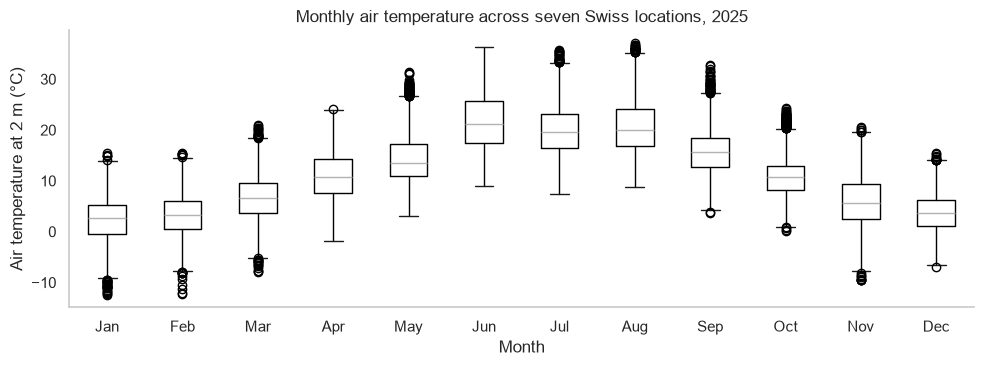

In [76]:
fig, ax = plt.subplots(figsize=(10, 4))
weather_2025.boxplot(column="temperature_2m", by="month", ax=ax, grid=False)
fig.suptitle("")
ax.set(title="Monthly air temperature across seven Swiss locations, 2025",
       xlabel="Month", ylabel="Air temperature at 2 m (°C)")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.tight_layout()
plt.show()

- The median hourly temperature rises from about **2.5 °C in January to a peak of 21 °C** in June. July and August are slightly cooler, with medians just below **20 °C**.

- Each box includes daytime and nighttime observations from all seven locations. Its spread therefore reflects variation across hours, days and locations.

### 5.2 How does shortwave radiation vary by hour of day?
We group shortwave radiation observations from all seven locations by recorded hour to examine the daily pattern.

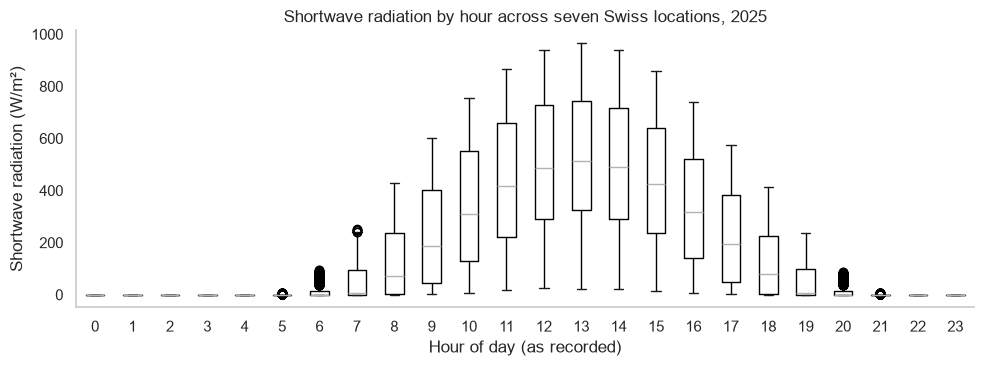

In [77]:
fig, ax = plt.subplots(figsize=(10, 4))
weather_2025.boxplot(column="shortwave_radiation", by="hour", ax=ax, grid=False)
fig.suptitle("")
ax.set(title="Shortwave radiation by hour across seven Swiss locations, 2025",
       xlabel="Hour of day (as recorded)", ylabel="Shortwave radiation (W/m²)")
plt.tight_layout()
plt.show()

- Median shortwave radiation is **0 W/m² overnight**, reaches its highest value of about **500 W/m² at 13:00**, and falls to almost **0 W/m² by 19:00**.

- A median of zero at a given hour means that at least half of the observations are zero. Some days or locations can still have positive radiation at that hour.